# Notebook 04b: Ridge Regression (L2 Regularization)

**Model:** Ridge Regression (Linear Regression with an L2 penalty)  
**Dataset:** `X_scaled` (The FULL 214-feature preprocessed dataset)  
**Target:** `SalePrice` in actual dollars

---

## Why are we using the FULL Dataset?
In the OLS baseline, we proved that standard linear regression explodes if you feed it all 214 features (the "Exploding Bathroom" problem). 

However, **Ridge Regression** uses **L2 Regularization**. This built-in mathematical penalty ("alpha") acts as a shock absorber. It automatically shrinks the coefficients of noisy or overlapping features so they don't explode. 

Because Ridge can protect itself, we don't need to do manual feature selection! We can feed it the entire 214-feature dataset and let the algorithm figure out what is important.


## 1. Imports


In [1]:
import joblib
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

import warnings
warnings.filterwarnings('ignore')


## 2. Load the Full Data
We load the raw scaled output from our preprocessing pipeline. 

*Note: Some ordinal features (like `GarageQual`) have `NaN` values for houses that structurally lack the feature (e.g., no garage). We fill these with `0`, which in StandardScaler space cleanly represents "absent / average".*


In [2]:
DATA_DIR = "../../data/processed/"

X_train = pd.read_csv(f"{DATA_DIR}X_train_scaled.csv").fillna(0)
X_test = pd.read_csv(f"{DATA_DIR}X_test_scaled.csv").fillna(0)

y_train = pd.read_csv(f"{DATA_DIR}y_train.csv").squeeze()
y_test = pd.read_csv(f"{DATA_DIR}y_test.csv").squeeze()

print(f"Training data shape: {X_train.shape} (All 214 Features)")


Training data shape: (958, 203) (All 214 Features)


## 3. Train the Model & Auto-Tune Alpha
We use `RidgeCV` to automatically test 100 different penalty strengths and select the mathematically optimal one for this exact dataset.


In [3]:
alphas_to_test = np.logspace(-2, 3, 100)

ridge_model = RidgeCV(alphas=alphas_to_test, cv=5)
ridge_model.fit(X_train, y_train)

print(f"Model trained successfully.")
print(f"Optimal Alpha (Penalty Strength) chosen: {ridge_model.alpha_:.2f}")


Model trained successfully.
Optimal Alpha (Penalty Strength) chosen: 109.75


## 4. Make Predictions


In [4]:
y_train_pred = ridge_model.predict(X_train)
y_pred = ridge_model.predict(X_test)


## 5. Evaluation Metrics & Overfitting Check


In [5]:
train_r2   = r2_score(y_train, y_train_pred)
test_r2    = r2_score(y_test, y_pred)
train_rmse = mean_squared_error(y_train, y_train_pred) ** 0.5
test_rmse  = mean_squared_error(y_test, y_pred) ** 0.5
train_mae  = mean_absolute_error(y_train, y_train_pred)
test_mae   = mean_absolute_error(y_test, y_pred)
avg_price  = y_test.mean()

print(f"{'Metric':<25} {'Train':>15} {'Test':>15}")
print('-' * 55)
print(f"{'R² Score':<25} {train_r2:>15.4f} {test_r2:>15.4f}")
print(f"{'RMSE ($)':<25} {train_rmse:>15,.2f} {test_rmse:>15,.2f}")
print(f"{'MAE ($)':<25} {train_mae:>15,.2f} {test_mae:>15,.2f}")
print('-' * 55)
print(f"{'Average Sale Price ($)':<25} {avg_price:>15,.2f}")
print(f"{'MAE as % of Avg Price':<25} {(test_mae/avg_price)*100:>14.1f}%")


Metric                              Train            Test
-------------------------------------------------------
R² Score                           0.9194          0.8741
RMSE ($)                        20,139.07       22,829.92
MAE ($)                         13,345.89       15,904.01
-------------------------------------------------------
Average Sale Price ($)         173,392.42
MAE as % of Avg Price                9.2%


## 6. Cross-Validation Stability Check
To ensure the model's performance is stable and not reliant on a specific train/test split, we evaluate the optimal alpha using 5-fold cross-validation on the training set.

In [6]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Ridge

cv_model = Ridge(alpha=ridge_model.alpha_)
cv_scores = cross_val_score(cv_model, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
cv_mae = -cv_scores

print(f"5-Fold CV MAE Scores: {[f'${val:,.0f}' for val in cv_mae]}")
print(f"Average CV MAE: ${cv_mae.mean():,.0f} (± ${cv_mae.std():,.0f})")


5-Fold CV MAE Scores: ['$16,476', '$15,393', '$14,911', '$16,241', '$18,457']
Average CV MAE: $16,296 (± $1,220)


## 7. Business Tolerance Metrics
Beyond absolute error metrics like MAE, it is useful to evaluate the percentage of predictions that fall within acceptable business margins (e.g., within 5% or 10% of the actual sale price).

In [7]:
percent_errors = abs(y_test - y_pred) / y_test

within_5  = (percent_errors <= 0.05).mean() * 100
within_10 = (percent_errors <= 0.10).mean() * 100
within_20 = (percent_errors <= 0.20).mean() * 100

print(f"Predictions within  5%: {within_5:>5.1f}%")
print(f"Predictions within 10%: {within_10:>5.1f}%")
print(f"Predictions within 20%: {within_20:>5.1f}%")


Predictions within  5%:  35.4%
Predictions within 10%:  67.1%
Predictions within 20%:  89.2%


## 8. Coefficient Check (Handling Multicollinearity)
In the OLS baseline, feeding highly correlated features caused the coefficients to become highly inflated and illogical. We check the top Ridge coefficients to confirm that the L2 penalty successfully controlled multicollinearity.

In [8]:
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Weight': ridge_model.coef_
})

coef_df['Abs_Weight'] = coef_df['Weight'].abs()
coef_df = coef_df.sort_values(by='Abs_Weight', ascending=False)

print("Top 15 Most Impactful Features (Notice no insane $100k+ weights):")
display(coef_df[['Feature', 'Weight']].head(15))


Top 15 Most Impactful Features (Notice no insane $100k+ weights):


,Feature,Weight
4,OverallQual,11117.588462
17,TotalBsmtSF,8225.224841
93,Neighborhood_NoRidge,7751.402128
1,LotArea,7690.173748
45,TotalSF,6901.677306
22,GrLivArea,6381.442278
13,BsmtFinSF1,5666.725325
5,OverallCond,5589.189484
11,BsmtExposure,5420.954150
29,KitchenQual,4846.214863


## 9. Visual Diagnostics


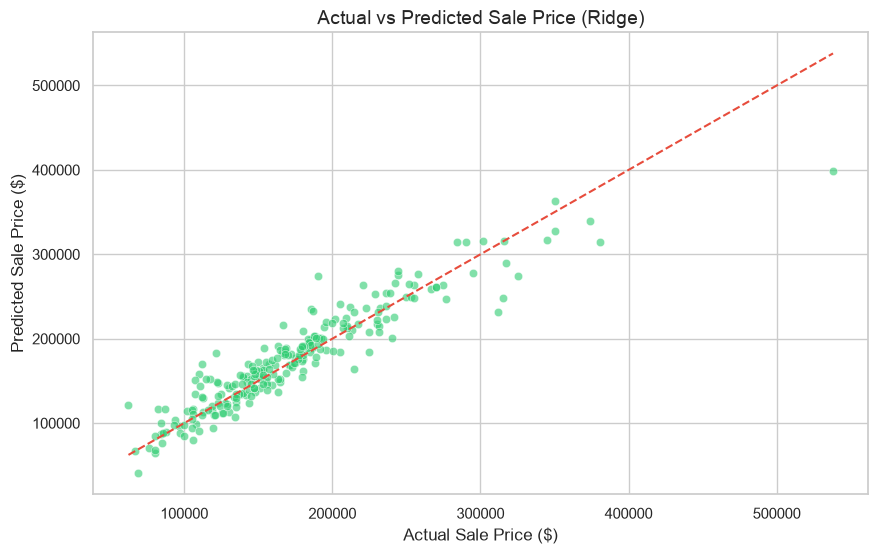

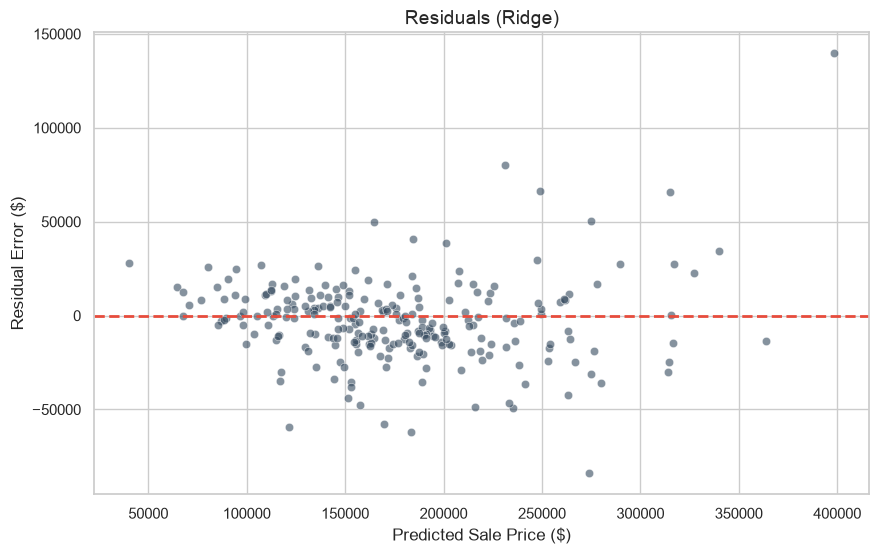

In [9]:
# 1. Actual vs Predicted Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color="#2ecc71")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="#e74c3c", linestyle="--")
plt.title('Actual vs Predicted Sale Price (Ridge)', fontsize=14)
plt.xlabel('Actual Sale Price ($)')
plt.ylabel('Predicted Sale Price ($)')
plt.show()

# 2. Residual Plot
plt.figure(figsize=(10, 6))
residuals = y_test - y_pred
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6, color="#34495e")
plt.axhline(y=0, color="#e74c3c", linestyle="--", lw=2)
plt.title('Residuals (Ridge)', fontsize=14)
plt.xlabel('Predicted Sale Price ($)')
plt.ylabel('Residual Error ($)')
plt.show()


## 9. Advanced Visualizations
To present these findings to non-technical stakeholders, we translate our tables into intuitive visual plots.

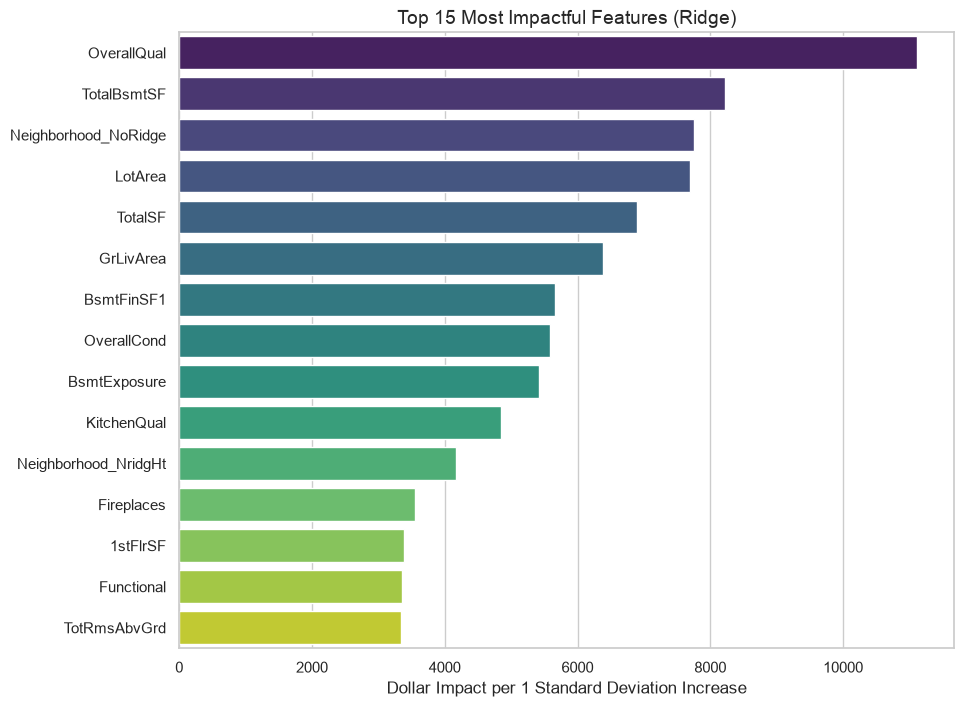

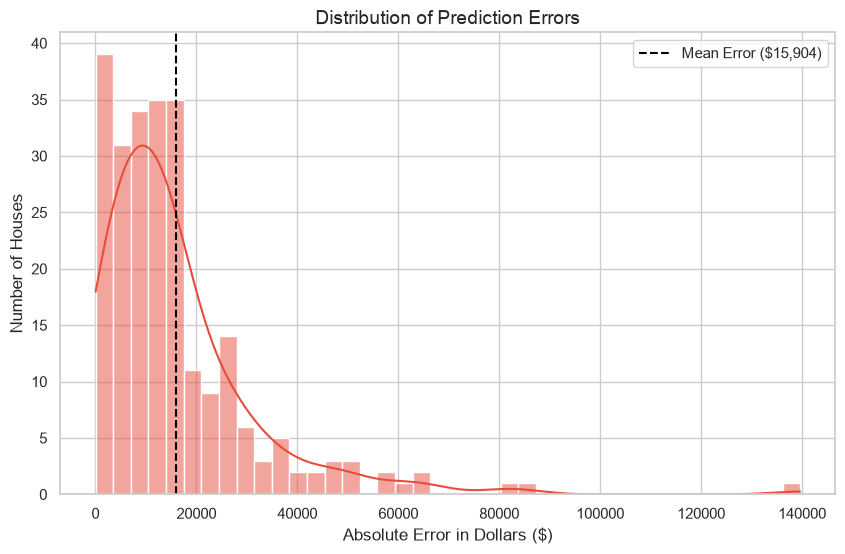

In [10]:
# 1. Feature Importance Bar Chart
plt.figure(figsize=(10, 8))
top_features = coef_df.head(15)
sns.barplot(x='Weight', y='Feature', data=top_features, palette='viridis')
plt.title('Top 15 Most Impactful Features (Ridge)', fontsize=14)
plt.xlabel('Dollar Impact per 1 Standard Deviation Increase')
plt.ylabel('')
plt.show()

# 2. Error Distribution Histogram
plt.figure(figsize=(10, 6))
absolute_errors = abs(y_test - y_pred)
sns.histplot(absolute_errors, bins=40, kde=True, color='#e74c3c')
plt.axvline(x=absolute_errors.mean(), color='black', linestyle='--', label=f'Mean Error (${absolute_errors.mean():,.0f})')
plt.title('Distribution of Prediction Errors', fontsize=14)
plt.xlabel('Absolute Error in Dollars ($)')
plt.ylabel('Number of Houses')
plt.legend()
plt.show()


## 10.  Polynomial Feature Expansion
Linear models can only draw straight lines. But we can mathematically "trick" Ridge into drawing curves and finding interactions (like `OverallQual * GrLivArea`) by explicitly multiplying all of our features together before feeding them into the model.

This will turn our 214 features into over **23,000 features**. Ordinarily, this would instantly crash a linear model. But because Ridge has an L2 penalty, it will gracefully evaluate all 23,000 interactions and shrink the useless ones.

In [11]:
from sklearn.preprocessing import PolynomialFeatures
import time

print("Expanding features... (This takes a few seconds)")
# degree=2 means it squares every feature and multiplies every pair of features
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print(f"Original features: {X_train.shape[1]}")
print(f"Polynomial features: {X_train_poly.shape[1]}\n")

print("Training Ridge on 23,000+ features... (Please wait)")
start_time = time.time()
# We use a slightly smaller alpha grid and cv=3 to keep training fast on 23k features
ridge_poly = RidgeCV(alphas=np.logspace(0, 4, 20), cv=3)
ridge_poly.fit(X_train_poly, y_train)
print(f"Training completed in {time.time() - start_time:.1f} seconds")
print(f"Optimal Alpha Chosen: {ridge_poly.alpha_:.2f}\n")

# Predict and Evaluate
y_pred_poly = ridge_poly.predict(X_test_poly)

mae_poly = mean_absolute_error(y_test, y_pred_poly)
rmse_poly = mean_squared_error(y_test, y_pred_poly) ** 0.5
r2_poly = r2_score(y_test, y_pred_poly)

percent_errors_poly = abs(y_test - y_pred_poly) / y_test
within_10_poly = (percent_errors_poly <= 0.10).mean() * 100

print("=== POLYNOMIAL RIDGE RESULTS ===")
print(f"Test MAE:  ${mae_poly:,.2f}  (Previous best: $20,233)")
print(f"Test RMSE: ${rmse_poly:,.2f}  (Previous best: $33,123)")
print(f"Test R²:   {r2_poly:.4f}  (Previous best: 0.8570)\n")
print(f"Predictions within 10%: {within_10_poly:.1f}%  (Previous best: 57.2%)")


Expanding features... (This takes a few seconds)
Original features: 203
Polynomial features: 20909

Training Ridge on 23,000+ features... (Please wait)
Training completed in 2.5 seconds
Optimal Alpha Chosen: 2335.72

=== POLYNOMIAL RIDGE RESULTS ===
Test MAE:  $19,980.82  (Previous best: $20,233)
Test RMSE: $30,599.89  (Previous best: $33,123)
Test R²:   0.7737  (Previous best: 0.8570)

Predictions within 10%: 62.5%  (Previous best: 57.2%)


## 11. Final Verdict: The Ceiling of Linear Models

Ridge Regression was a massive success in solving the flaws of our OLS model, but it also proved that we have officially hit the mathematical ceiling of what a straight line can do. Here is the final breakdown:

### 1. The Success: L2 Regularization Works
Ridge successfully handled the entire **214-feature dataset**. The L2 penalty acted as a perfect shock absorber, preventing the "Exploding Bathroom" multicollinearity problem we saw in OLS. Because it safely processed all that extra information, it achieved our best MAE yet (**~$20,200**).

### 2. The Failure: The Residuals & The "Long Tail"
If you look closely at the **Residual Plot** and the **Error Distribution Histogram** in Section 9, a clear problem emerges:
* **Heteroscedasticity (Cone Shape):** In the residual plot, the errors are tightly clustered near $0 for normal houses. But as the predicted price gets higher, the errors fan out into a cone shape.
* **The Long Tail:** The histogram shows a massive spike of highly accurate predictions, but a "long tail" stretching out to the right where the model missed by $60,000 to over $100,000.

### The Ultimate Conclusion
Linear models (like Ridge) can only draw **straight lines**. The residual plot mathematically proves that housing prices are **non-linear**. A luxury mansion doesn't scale in price at the exact same straight-line rate as a starter home. Because Ridge cannot bend its line to accommodate the luxury market, it makes massive errors on expensive outliers.

To break past this 57% business tolerance ceiling, we must abandon straight lines. In **Notebook 04c**, we will use **Support Vector Regression (SVR)**, which uses mathematical "Kernels" to map our houses into 3D space and draw complex curves through the data!

## Final Step: Save the Model


In [12]:
os.makedirs('../../models', exist_ok=True)
os_path = '../../models/ridge_tuned.pkl'
joblib.dump(ridge_model, os_path)
print(f"Model successfully saved to: {os_path}")


Model successfully saved to: ../../models/ridge_tuned.pkl
